
# 1. Error Analysis

This notebook examines the classification errors made by the selected Linear Support Vector Machine (Linear SVM) model. The analysis uses the saved validation predictions from the strongest configuration identified during model comparison: TF-IDF features with the full-message representation.

The purpose is to understand where the classifier performs well, which categories account for a larger proportion of its errors, and which pairs of topics are most frequently confused. The analysis also considers individual misclassified record identifiers to establish a basis for subsequent manual investigation.

The selected model achieved a validation accuracy of approximately 91.47% and a macro F1 score of 0.9138 across the twenty 20 Newsgroups categories. These aggregate metrics provide a useful starting point, but they do not reveal how errors are distributed across individual classes.

This notebook therefore examines overall performance, class-level metrics, directional confusion pairs, and selected misclassified records.

For privacy and responsible reporting, the generated error-analysis reports do not contain source message text. Selected records are identified by their record IDs and classification labels. Any excerpts intended for publication would require separate manual review and appropriate redaction.

All analysis is based on the fixed development validation partition. The official test set is not used, and no model training is performed in this notebook.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "results/logs/error_analysis.json").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

SUMMARY_PATH = PROJECT_ROOT / "results/logs/error_analysis.json"
PER_CLASS_PATH = PROJECT_ROOT / "results/tables/error_analysis_per_class.csv"
CONFUSION_PAIRS_PATH = (
    PROJECT_ROOT / "results/tables/error_analysis_confusion_pairs.csv"
)
EXAMPLES_PATH = (
    PROJECT_ROOT / "results/tables/error_analysis_misclassified_examples.csv"
)

for path in [
    SUMMARY_PATH,
    PER_CLASS_PATH,
    CONFUSION_PAIRS_PATH,
    EXAMPLES_PATH,
]:
    assert path.is_file(), f"Required error-analysis output not found: {path}"

print(f"Project root: {PROJECT_ROOT}")
print(f"Summary: {SUMMARY_PATH}")
print(f"Per-class results: {PER_CLASS_PATH}")
print(f"Confusion pairs: {CONFUSION_PAIRS_PATH}")
print(f"Misclassified examples: {EXAMPLES_PATH}")

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Summary: /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/error_analysis.json
Per-class results: /home/nkululekocyrilcele/projects/topicsense-nlp/results/tables/error_analysis_per_class.csv
Confusion pairs: /home/nkululekocyrilcele/projects/topicsense-nlp/results/tables/error_analysis_confusion_pairs.csv
Misclassified examples: /home/nkululekocyrilcele/projects/topicsense-nlp/results/tables/error_analysis_misclassified_examples.csv


## 1.1 Loading and Validating the Error-Analysis Results

The error-analysis script generates a consolidated JSON report together with separate CSV files for per-class performance, confusion pairs, and selected misclassified records.

The JSON report contains the overall validation metrics, class-level statistics, directional confusion counts, and selected record identifiers. The CSV files provide convenient tabular versions of these results for inspection and visualisation.

The following cell loads the generated outputs and checks that their contents are consistent with the expected experiment. These checks help ensure that the notebook uses the intended Linear SVM validation results rather than an outdated or unrelated report.

In [2]:
with SUMMARY_PATH.open("r", encoding="utf-8") as file:
    error_analysis = json.load(file)

metadata = error_analysis["metadata"]
metrics = error_analysis["metrics"]

per_class_df = pd.read_csv(PER_CLASS_PATH)
confusion_pairs_df = pd.read_csv(CONFUSION_PAIRS_PATH)
examples_df = pd.read_csv(EXAMPLES_PATH)

assert metadata["dataset"] == "20newsgroups"
assert metadata["selected_run_id"] == "linear_svm__tfidf__full_message"
assert metadata["validation_documents"] == 2263
assert metadata["misclassified_documents"] == 193
assert metadata["correctly_classified_documents"] == 2070
assert metadata["class_count"] == 20
assert metadata["test_data_used"] is False

assert len(per_class_df) == 20
assert len(examples_df) == len(error_analysis["misclassified_examples"])

assert "text" not in examples_df.columns
assert all(
    "text" not in example
    for example in error_analysis["misclassified_examples"]
)

assert set(per_class_df["class_label"]) == set(
    row["class_label"] for row in error_analysis["per_class"]
)

assert set(confusion_pairs_df.columns) == {
    "actual_label",
    "predicted_label",
    "document_count",
}

print("Error-analysis validation passed.")
print(f"Selected model: {metadata['selected_run_id']}")
print(f"Validation documents: {metadata['validation_documents']:,}")
print(f"Misclassified documents: {metadata['misclassified_documents']:,}")
print(f"Correctly classified documents: {metadata['correctly_classified_documents']:,}")
print(f"Number of classes: {metadata['class_count']}")
print(f"Selected error records: {len(examples_df):,}")
print(f"Official test data used: {metadata['test_data_used']}")

Error-analysis validation passed.
Selected model: linear_svm__tfidf__full_message
Validation documents: 2,263
Misclassified documents: 193
Correctly classified documents: 2,070
Number of classes: 20
Selected error records: 168
Official test data used: False


### Interpreting the Validation Metadata

The validation report contains 2,263 documents distributed across twenty categories. The selected Linear SVM correctly classifies 2,070 documents and misclassifies 193.

The report confirms that the selected configuration is `linear_svm__tfidf__full_message`, matching the strongest configuration identified in the preceding model-comparison notebook.

The generated examples are identifiers and labels rather than copies of the original messages. This keeps the exported reports free of source message content while preserving enough information to identify records for a separately controlled manual review.

The validation checks also confirm that the official test set was not used. Consequently, the findings in this notebook describe development-set errors and should not be interpreted as final test-set performance.

## 1.2 Overall Classification Performance

The first stage examines the overall validation metrics of the selected model.

Accuracy measures the proportion of all validation documents classified correctly. Precision measures the proportion of predicted class assignments that are correct, while recall measures the proportion of actual documents from each class that the model successfully identifies.

Macro F1 gives equal weight to each class when calculating the overall F1 score. Weighted F1 accounts for the number of documents in each class. Both are useful here because they provide complementary views of performance across the twenty categories.

The next cell presents these metrics together with the number of correctly and incorrectly classified documents.

In [3]:
overall_metrics = pd.DataFrame(
    [
        {
            "metric": "Accuracy",
            "value": metrics["accuracy"],
        },
        {
            "metric": "Macro precision",
            "value": metrics["macro_precision"],
        },
        {
            "metric": "Macro recall",
            "value": metrics["macro_recall"],
        },
        {
            "metric": "Macro F1",
            "value": metrics["macro_f1"],
        },
        {
            "metric": "Weighted F1",
            "value": metrics["weighted_f1"],
        },
    ]
)

display(overall_metrics)

print(f"Correct predictions: {metadata['correctly_classified_documents']:,}")
print(f"Incorrect predictions: {metadata['misclassified_documents']:,}")
print(f"Total validation documents: {metadata['validation_documents']:,}")

,metric,value
0,Accuracy,0.9147
1,Macro precision,0.9170
2,Macro recall,0.9125
3,Macro F1,0.9138
4,Weighted F1,0.9147


Correct predictions: 2,070
Incorrect predictions: 193
Total validation documents: 2,263


### Interpreting Overall Performance

The selected Linear SVM achieves an accuracy of 0.9147 and a macro F1 score of 0.9138. Its macro precision is 0.9170, while macro recall is 0.9125. Weighted F1 is 0.9147.

The relatively small difference between macro F1 and weighted F1 indicates that the overall result is not driven solely by the more frequently represented categories. Performance remains strong when each category receives equal weight.

Nevertheless, the aggregate results conceal differences in class-level performance. A model can achieve a high overall score while still making a disproportionate number of mistakes in particular categories. The next section investigates this distribution.

## 1.3 Class-Level Error Analysis

Overall metrics do not identify which categories contribute most to classification errors. Class-level analysis provides a more detailed view by examining the number of validation documents, correct predictions, misclassifications, false positives, precision, recall, and F1 score for each category.

Recall is particularly relevant when investigating missed documents because it indicates how many actual documents belonging to a category were correctly identified.

Precision provides a complementary perspective. A category may have reasonable recall but lower precision if documents from other categories are frequently assigned to it.

The following table ranks the categories by F1 score, making it easier to identify the strongest and weakest areas of model performance.

In [4]:
per_class_df = per_class_df.sort_values(
    "f1_score",
    ascending=False,
).reset_index(drop=True)

display(
    per_class_df[
        [
            "class_label",
            "support",
            "correct_predictions",
            "misclassified_documents",
            "false_positives",
            "precision",
            "recall",
            "f1_score",
        ]
    ]
)

,class_label,support,correct_predictions,misclassified_documents,false_positives,precision,recall,f1_score
0,talk.politics.mideast,113,113,0,4,0.9658,1.0000,0.9826
1,sci.space,118,115,3,2,0.9829,0.9746,0.9787
2,sci.crypt,119,116,3,3,0.9748,0.9748,0.9748
3,rec.motorcycles,120,114,6,4,0.9661,0.9500,0.9580
4,talk.politics.guns,109,107,2,8,0.9304,0.9817,0.9554
5,rec.sport.hockey,120,112,8,3,0.9739,0.9333,0.9532
6,rec.sport.baseball,119,115,4,8,0.9350,0.9664,0.9504
7,soc.religion.christian,120,116,4,10,0.9206,0.9667,0.9431
8,alt.atheism,96,89,7,4,0.9570,0.9271,0.9418
9,talk.politics.misc,93,88,5,6,0.9362,0.9462,0.9412


### Interpreting Class-Level Performance

The class-level results show that performance varies across the twenty categories.

For example, `alt.atheism` achieves an F1 score of approximately 0.9418 in the displayed results. In contrast, `comp.sys.ibm.pc.hardware` achieves an F1 score of approximately 0.7830, indicating a more challenging classification task for that category.

The weaker results among some computer-related categories are consistent with the possibility of overlapping terminology and related subject matter. However, the class-level metrics alone cannot establish the reasons for these errors.

The distinction between false positives and misclassified documents is also important. A category may lose documents to other predictions while simultaneously receiving documents incorrectly assigned from other categories. These two forms of error are reflected separately in the report.

The following visualisations provide a clearer comparison of the distribution of class-level F1 scores and the number of misclassified documents.

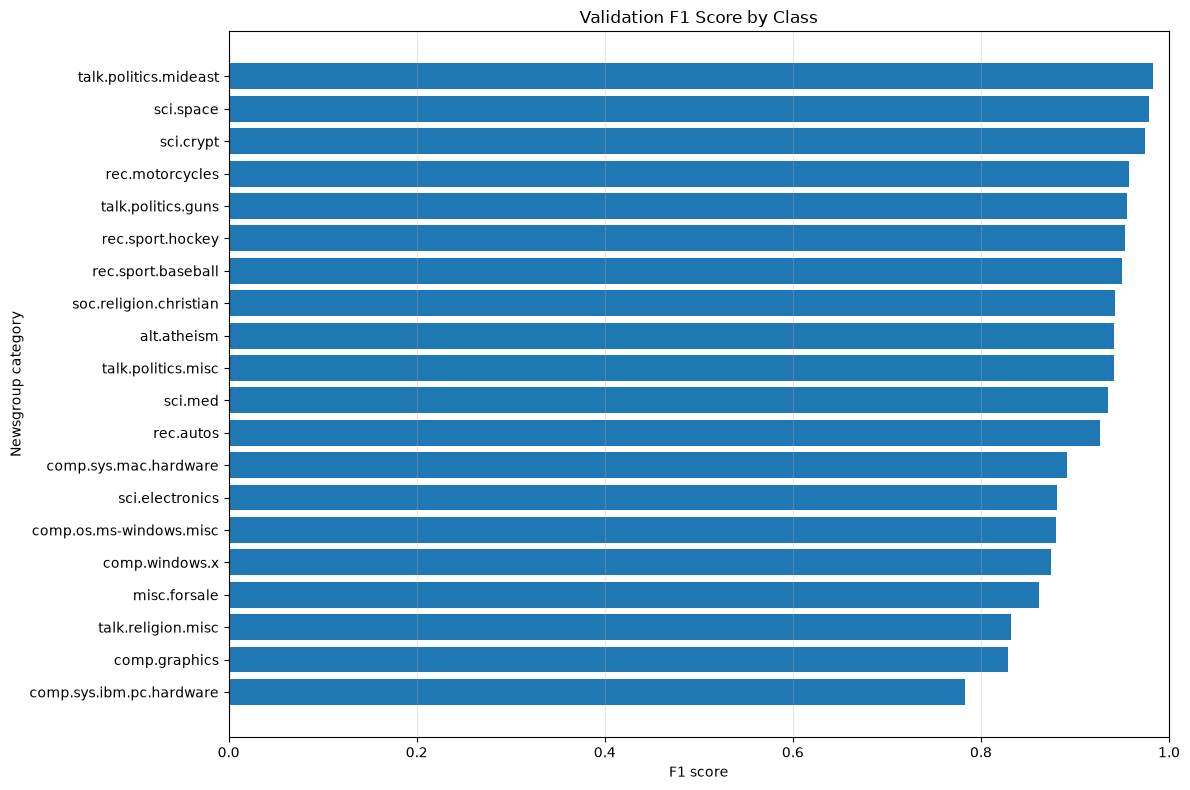

In [5]:
fig, ax = plt.subplots(figsize=(12, 8))

plot_df = per_class_df.sort_values("f1_score", ascending=True)

ax.barh(
    plot_df["class_label"],
    plot_df["f1_score"],
)

ax.set_title("Validation F1 Score by Class")
ax.set_xlabel("F1 score")
ax.set_ylabel("Newsgroup category")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

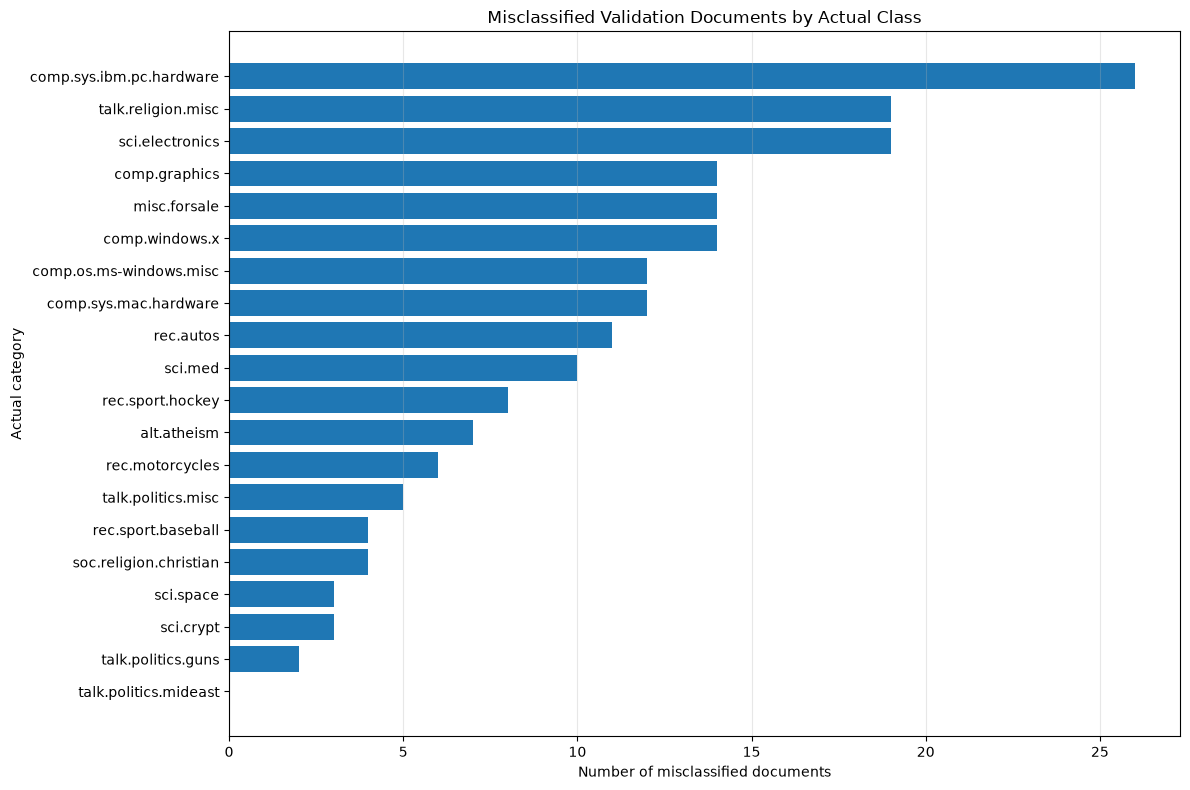

In [6]:
fig, ax = plt.subplots(figsize=(12, 8))

error_plot_df = per_class_df.sort_values(
    "misclassified_documents",
    ascending=True,
)

ax.barh(
    error_plot_df["class_label"],
    error_plot_df["misclassified_documents"],
)

ax.set_title("Misclassified Validation Documents by Actual Class")
ax.set_xlabel("Number of misclassified documents")
ax.set_ylabel("Actual category")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpreting the Class-Level Visualisations

The F1 score chart makes the variation in classification performance across categories visible. The model performs particularly well on several categories, while some computer-related categories show comparatively lower F1 scores.

The misclassification chart provides a different perspective by showing the number of incorrect predictions for each actual category. These counts depend partly on the number of validation documents available for each category, so they should be considered alongside the support values in the class-level table.

Together, the visualisations suggest that model errors are not distributed uniformly across the dataset. This makes it useful to examine the specific predicted categories responsible for the largest directional confusion counts.

## 1.4 Most Frequent Confusion Pairs

A confusion pair identifies an actual category and the different category predicted by the classifier. These are directional relationships: confusing category A with category B is not necessarily as frequent as confusing category B with category A.

The analysis ranks these pairs by the number of validation documents assigned to the incorrect category.

This helps identify recurring classification difficulties that may be hidden by aggregate metrics. It is particularly useful when categories contain related terminology or discuss overlapping subject matter.

In [7]:
confusion_pairs_df = confusion_pairs_df.sort_values(
    "document_count",
    ascending=False,
).reset_index(drop=True)

display(confusion_pairs_df.head(15))

,actual_label,predicted_label,document_count
0,talk.religion.misc,soc.religion.christian,8
1,comp.graphics,comp.sys.ibm.pc.hardware,7
2,comp.sys.ibm.pc.hardware,comp.graphics,7
3,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,7
4,sci.electronics,comp.sys.ibm.pc.hardware,6
5,comp.windows.x,comp.os.ms-windows.misc,5
6,comp.graphics,comp.windows.x,4
7,comp.sys.ibm.pc.hardware,comp.windows.x,4
8,rec.sport.hockey,rec.sport.baseball,4
9,comp.os.ms-windows.misc,comp.graphics,3


### Interpreting the Confusion Pairs

The most frequent directional confusion involves `talk.religion.misc` being classified as `soc.religion.christian`, with eight validation documents assigned incorrectly in this direction.

Several prominent errors occur among computer-related categories. Seven `comp.graphics` documents are classified as `comp.sys.ibm.pc.hardware`, and another seven errors occur in the opposite direction. The results also show confusion between `comp.sys.ibm.pc.hardware` and `comp.os.ms-windows.misc`.

Other notable errors occur between `sci.electronics` and `comp.sys.ibm.pc.hardware`, as well as between the two sports categories `rec.sport.hockey` and `rec.sport.baseball`.

These patterns suggest that related terminology and overlapping discussion topics may contribute to classification difficulty. However, confusion counts alone cannot establish the reason for an individual prediction.

The directional nature of the results is important. For example, the seven errors from `comp.graphics` to `comp.sys.ibm.pc.hardware` should not be combined with the seven errors in the opposite direction when interpreting each category's individual recall.

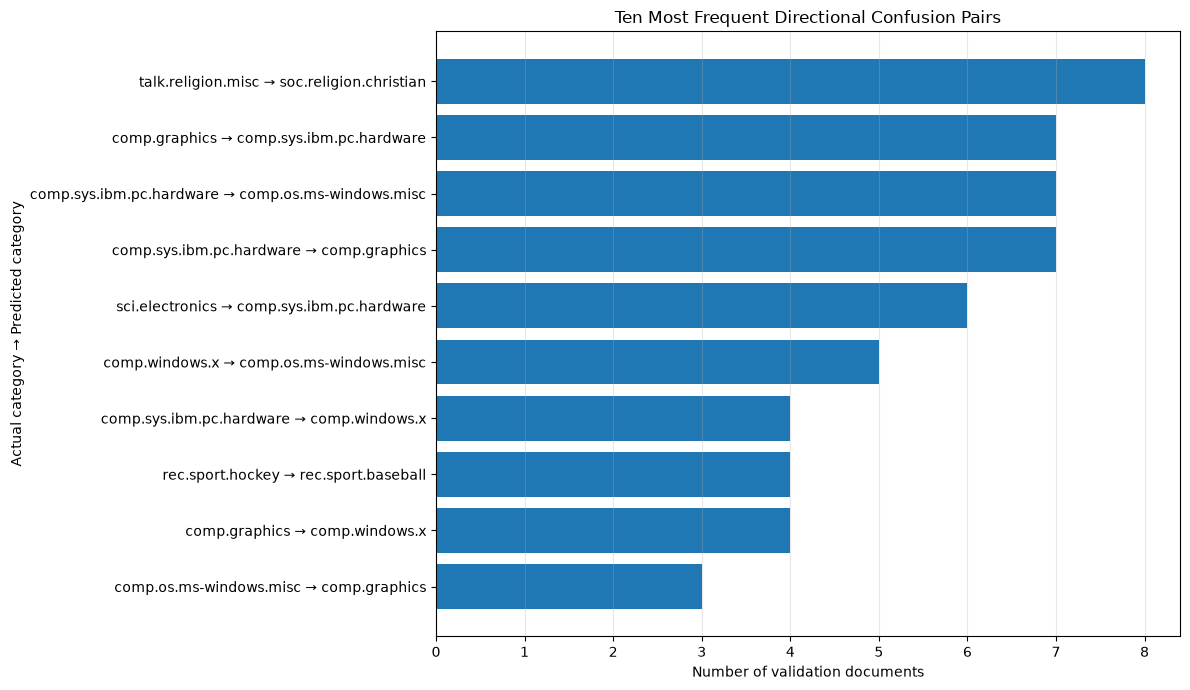

In [8]:
top_confusions = confusion_pairs_df.head(10).copy()

top_confusions["confusion_pair"] = (
    top_confusions["actual_label"]
    + " → "
    + top_confusions["predicted_label"]
)

fig, ax = plt.subplots(figsize=(12, 7))

plot_df = top_confusions.sort_values(
    "document_count",
    ascending=True,
)

ax.barh(
    plot_df["confusion_pair"],
    plot_df["document_count"],
)

ax.set_title("Ten Most Frequent Directional Confusion Pairs")
ax.set_xlabel("Number of validation documents")
ax.set_ylabel("Actual category → Predicted category")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpreting the Confusion-Pair Visualisation

The chart highlights the ten most frequent directional classification errors. The leading confusion is between the two religion-related categories, followed by several computer-related category pairs.

The visualisation reinforces the observation that the model's errors are concentrated in a number of recurring category relationships rather than being distributed evenly across all possible pairs.

This does not necessarily indicate that the model has learned incorrect features. Some documents may genuinely contain terminology associated with more than one category, and the newsgroup labels reflect their assigned discussion destinations rather than perfectly separated semantic topics.

A more detailed investigation would require reviewing the original messages in a controlled environment. The current reports deliberately exclude source text, so the notebook does not make unsupported claims about individual message content.

## 1.5 Selected Misclassified Records

The error-analysis pipeline also selects a limited number of misclassified records from the most frequent confusion pairs. The configuration allows up to three examples per pair.

The selected records are identified using their dataset record IDs, actual labels, predicted labels, and review status. Source message text is intentionally excluded from both the JSON and CSV reports.

This approach preserves the ability to locate and investigate particular records later without including potentially sensitive message content in the generated analysis outputs.

In [9]:
display(
    examples_df[
        [
            "record_id",
            "actual_label",
            "predicted_label",
            "excerpt_review_status",
        ]
    ].head(20)
)

print(f"Total selected records: {len(examples_df):,}")
print(
    "Review status:",
    examples_df["excerpt_review_status"].value_counts().to_dict(),
)

,record_id,actual_label,predicted_label,excerpt_review_status
0,20newsgroups-train-00751,talk.religion.misc,soc.religion.christian,withheld_pending_manual_review
1,20newsgroups-train-01716,talk.religion.misc,soc.religion.christian,withheld_pending_manual_review
2,20newsgroups-train-02642,talk.religion.misc,soc.religion.christian,withheld_pending_manual_review
3,20newsgroups-train-05238,comp.graphics,comp.sys.ibm.pc.hardware,withheld_pending_manual_review
4,20newsgroups-train-06326,comp.graphics,comp.sys.ibm.pc.hardware,withheld_pending_manual_review
5,20newsgroups-train-06512,comp.graphics,comp.sys.ibm.pc.hardware,withheld_pending_manual_review
6,20newsgroups-train-02405,comp.sys.ibm.pc.hardware,comp.graphics,withheld_pending_manual_review
7,20newsgroups-train-02425,comp.sys.ibm.pc.hardware,comp.graphics,withheld_pending_manual_review
8,20newsgroups-train-03553,comp.sys.ibm.pc.hardware,comp.graphics,withheld_pending_manual_review
9,20newsgroups-train-03891,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,withheld_pending_manual_review


Total selected records: 168
Review status: {'withheld_pending_manual_review': 168}


### Interpreting the Selected Misclassified Records

The report contains 168 selected records, each linked to its actual and predicted category.

The selected records provide traceability between the aggregate confusion analysis and the original dataset. For example, the first displayed record belongs to `talk.religion.misc` but was predicted as `soc.religion.christian`.

The review status `withheld_pending_manual_review` indicates that message excerpts have not been approved for publication. The records are therefore suitable for identifying cases for further investigation, but they do not constitute a qualitative review of the original messages.

This distinction is important. The current notebook examines quantitative error patterns and record-level classification outcomes. It does not claim to have established the linguistic reasons behind individual misclassifications.
